# Tarefa 3 — Clustering de vítimas: K-Means

Em um cenário de desastre, organizar as vítimas em grupos pode apoiar a divisão
do trabalho entre equipes de socorro. Nesta tarefa, investigamos como agrupar
as **410 vítimas** do cenário VictSim `75x75_410v`, considerando sua localização
e a probabilidade estimada de sobrevivência.

Clustering é uma forma de **aprendizado não supervisionado**: os grupos são
construídos a partir da semelhança entre características, sem rótulos prévios de
pertencimento. Embora algumas características sejam estimadas por modelos
supervisionados, não conhecemos uma classificação verdadeira dos clusters.

O experimento possui duas partes. Primeiro, avaliamos K-Means apenas com
`x_rel` e `y_rel`, estabelecendo uma referência espacial. Depois, acrescentamos
`sobr` para investigar se a condição estimada das vítimas modifica essa divisão.
Comparamos medidas de compacidade e separação, interpretamos os grupos e
discutimos seu possível uso no socorro.

As MLPs das [Tarefas 1](01%20-%20Classificador.ipynb) e
[2](02%20-%20Regressor.ipynb) fornecem `tri` e `sobr`, respectivamente.
O [enunciado da Tarefa 3](docs/enunciados/TO3_enunciado_cluster.pdf) define o
cenário e as restrições dos agentes. O escopo computacional é o agrupamento;
atribuição de agentes, rotas e sequência de atendimento serão discutidas
conceitualmente. Para reproduzir o experimento, execute as células em ordem,
com a raiz do repositório como diretório de trabalho e o Python de `.venv`.

## 1. Configuração do experimento

O K-Means depende da escolha inicial dos centroides e pode convergir para
soluções diferentes. Utilizamos inicialização `k-means++`, que favorece centros
iniciais afastados, e **30 inicializações por K**, mantendo a solução com menor
inércia. A semente 42 permite repetir essas escolhas aleatórias no mesmo ambiente.

Todos os ajustes usam o algoritmo de Lloyd, limite de 500 iterações e tolerância
`1e-4`. Manter esses parâmetros constantes permite atribuir as diferenças entre
os resultados à variação de K. As funções de `src/clustering.py` implementam
as operações de inferência, agrupamento, avaliação e visualização utilizadas
nas próximas seções.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import silhouette_score

from src.clustering import (
    SEED, FEATURES, ESPACIAIS, PRINCIPAIS, carregar_mapa, carregar_modelos, inferir,
    padronizar, avaliar_k, localizar_cotovelo, comparar_parametrizacoes,
    numerar_clusters, resumir_clusters, analisar_geometria, plotar_avaliacao, plotar_espaco,
    plotar_silhuetas, plotar_grid, exportar_clusters, validar_clusters,
)

%matplotlib inline

BASE = Path.cwd()
CAMINHO_MAPA = BASE / "dados/map.csv"
RESULTADOS = BASE / "resultados/clustering"
RESULTADOS.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
pd.set_option("display.float_format", "{:.6f}".format)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 11,
    "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.fontsize": 11, "legend.title_fontsize": 11, "figure.titlesize": 11,
})

## 2. Caracterização do mapa e preparação dos dados

O arquivo `dados/map.csv` descreve as **5.625 células** de um ambiente 75 × 75.
Cada linha contém coordenadas, dificuldade do terreno e, quando existe uma
vítima, seu identificador e sinais vitais. Células com `id = -1` não representam
vítimas; portanto, selecionamos **`id >= 0`**, incluindo a vítima de ID zero.

O atributo `obst = 100` indica parede intransponível; os demais valores em
`]0, 3]` representam dificuldades transitáveis. Verificamos identificadores
únicos, características finitas e ausência de vítimas em paredes. Essa seleção
separa vítimas de células vazias: nenhuma vítima é removida por ser atípica.

`x_rel` e `y_rel` são coordenadas relativas à base, localizada em `(0, 0)` nesse
referencial e em `(30, 40)` no grid absoluto. `x_rel` representa colunas e
`y_rel`, linhas que crescem **para baixo**. Os valores iniciais `tri = -1` e
`sobr = -1` indicam que essas características precisam ser estimadas.

In [2]:
mapa, vitimas = carregar_mapa(CAMINHO_MAPA)
display(vitimas[["id", "x_rel", "y_rel"] + FEATURES].head())
display(pd.Series({
    "Células": len(mapa), "Vítimas": len(vitimas),
    "Sem vítima": int((mapa.id == -1).sum()), "Paredes": int((mapa.obst == 100).sum()),
    "Vítimas de até 12 anos": int((vitimas.idade <= 12).sum()),
    "Menor ID": int(vitimas.id.min()), "Maior ID": int(vitimas.id.max()),
}, name="Cenário").to_frame())

,id,x_rel,y_rel,idade,fc,fr,pas,spo2,temp,pr,sg,fx,queim
0,0,-30,3,33,111,10,184,89,32.200000,0,2,0,1
1,1,-30,30,9,102,19,127,91,37.100000,1,1,1,2
2,2,-29,27,8,120,23,104,97,38.100000,1,0,0,2
3,3,-28,-11,5,84,11,125,95,36.500000,1,0,0,0
4,4,-28,16,7,128,32,77,79,39.900000,0,1,1,1


,Cenário
Células,5625
Vítimas,410
Sem vítima,5215
Paredes,555
Vítimas de até 12 anos,106
Menor ID,0
Maior ID,409


## 3. Estimativa da triagem e da sobrevivência

As tarefas anteriores comparam árvores de decisão CART e redes neurais MLP
por validação cruzada. Suas melhores configurações, identificadas por
E (equilibrada), apresentam os seguintes resultados:

| Critério de validação | Melhor CART (E) | Melhor MLP (E) |
|---|---:|---:|
| Classificação — F1 macro médio (maior é melhor) | 0,968595 | **0,979212** |
| Regressão — MSE médio (menor é melhor) | 0,002332 | **0,001773** |

Esses resultados fundamentam a reutilização das MLPs, ambas com camadas
`(32, 16)` e ativação ReLU. Os modelos permanecem fixos: o mapa é um novo
conjunto de entrada para inferência, sem treinamento adicional.

Selecionamos exatamente as dez entradas, na ordem do treinamento:
`idade, fc, fr, pas, spo2, temp, pr, sg, fx, queim`.
`gcs`, `avpu`, `tri` e `sobr` não participam dessas entradas. O classificador
inclui a padronização em seu `Pipeline`; para a regressão, aplicamos
`transform` com o scaler previamente ajustado e depois `predict`.
Ajustar novamente esses scalers ao mapa alteraria a representação esperada
pelos modelos.

`tri` estima a classe START: 0 (verde), 1 (amarela), 2 (vermelha) ou 3 (preta).
`sobr` estima a probabilidade de sobrevivência.
Como são previsões, ambas carregam os erros dos modelos anteriores.
As saídas de `sobr` são utilizadas sem clipping; uma previsão fora de `[0, 1]`
interromperia a execução para investigação, em vez de ser corrigida silenciosamente.

In [3]:
classificador, regressor, scaler_regressor = carregar_modelos(BASE)
vitimas = inferir(vitimas, classificador, regressor, scaler_regressor)
assert len(vitimas) == 410
display(vitimas[["id", "tri", "sobr"]].head())
contagem_tri = vitimas.tri.value_counts().reindex(range(4), fill_value=0)
display(contagem_tri.rename("Vítimas").to_frame())
display(vitimas.sobr.describe().to_frame())
print("Previsões fora de [0,1]:", int((~vitimas.sobr.between(0, 1)).sum()))
print("Valores -1 em vítimas processadas:", int((vitimas[["tri", "sobr"]] == -1).sum().sum()))

,id,tri,sobr
0,0,2,0.543082
1,1,1,0.772000
2,2,1,0.795603
3,3,0,0.944326
4,4,2,0.454172


,Vítimas
tri,
0,101
1,105
2,109
3,95


,sobr
count,410.000000
mean,0.618204
std,0.267654
min,0.163757
25%,0.384282
50%,0.695594
75%,0.878773
max,0.967019


Previsões fora de [0,1]: 0
Valores -1 em vítimas processadas: 0


As inferências classificam **101 vítimas como verdes, 105 como amarelas,
109 como vermelhas e 95 como pretas**. A sobrevivência estimada varia de
0,163757 a 0,967019, com média 0,618204. Não há previsões fora de `[0, 1]`
ou valores ausentes de `tri`/`sobr` nas vítimas processadas. Isso permite
utilizar todas as 410 observações, sem significar que as previsões estejam
isentas de erro: não há avaliação de acurácia ou MSE neste mapa sem alvos
conhecidos.

## 4. Experimento básico: agrupamento espacial

O experimento de referência utiliza somente **`[x_rel, y_rel]`**. Para um K
definido, o K-Means alterna duas operações: atribuir cada vítima ao centroide
mais próximo e recalcular cada centroide pela média dos pontos atribuídos.
O processo procura reduzir a soma das distâncias quadráticas aos centros:

$$J = \sum_{i=1}^{N}\|z_i-\mu_{c(i)}\|^2,$$

onde $z_i$ é a representação da vítima, $c(i)$ indica seu cluster e
$\mu_{c(i)}$ é o centroide correspondente. O método favorece grupos compactos
segundo a distância euclidiana no espaço utilizado.

Aplicamos `StandardScaler` às coordenadas: cada eixo passa a ter média zero
e variância populacional um. Isso equilibra a contribuição das dispersões dos
eixos. A distância resultante é medida em unidades padronizadas, podendo
diferir da distância euclidiana em células. O scaler é ajustado **uma vez**
às 410 vítimas e reutilizado para todos os K de 2 a 12.

### Compacidade e separação

**Erro de agrupamento.** `inertia_` corresponde a $J$, a SSE convencional.
Como o enunciado menciona a raiz quadrada do erro quadrático, adotamos na coluna
**SSE do enunciado** a medida $\sqrt{J}$. Ela difere de
RMSE $=\sqrt{J/N}$. Quanto menor o erro, mais próximos os pontos estão dos
centroides, mas aumentar K permite reduzir esse erro sem necessariamente
produzir uma divisão mais útil.

**Coeficiente de silhueta.** Para a vítima $i$, $a_i$ é sua distância média às
demais vítimas do próprio cluster e $b_i$ é a menor distância média a outro
cluster. Assim,

$$s_i=\frac{b_i-a_i}{\max(a_i,b_i)},\qquad S_g=\frac{1}{N}\sum_{i=1}^{N}s_i.$$

Valores próximos de **1** indicam coesão e separação elevadas; próximos de
**0**, proximidade à fronteira entre grupos; valores **negativos** indicam
maior proximidade média a outro grupo. $S_g$ dá o mesmo peso a cada vítima;
clusters maiores contribuem com mais observações para essa média. Essas medidas
devem ser interpretadas no espaço e na escala em que foram calculadas.

,K,SSE,silhueta
0,2,22.062567,0.391521
1,3,17.068783,0.451453
2,4,13.241405,0.476091
3,5,11.709833,0.480188
4,6,10.613589,0.473169
5,7,9.628205,0.457625
6,8,8.963764,0.416997
7,9,8.441441,0.420135
8,10,8.013923,0.404867
9,11,7.564157,0.419831


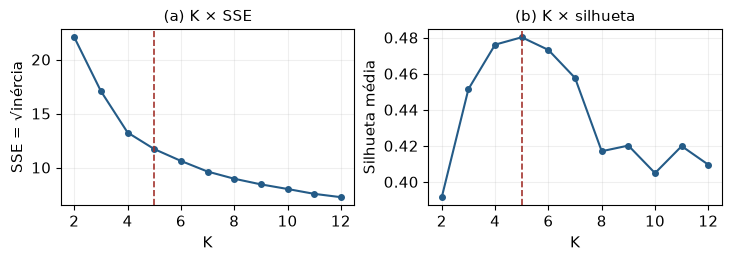

In [4]:
X_espacial, scaler_espacial = padronizar(vitimas, ESPACIAIS)
tabela_espacial, modelos_espaciais, silhuetas_espaciais = avaliar_k(X_espacial)
k_espacial, distancias_espaciais = localizar_cotovelo(tabela_espacial)
tabela_espacial["distancia_cotovelo"] = distancias_espaciais
display(tabela_espacial[["K", "SSE", "silhueta"]])
fig = plotar_avaliacao(tabela_espacial, RESULTADOS / "avaliacao_espacial.png", k_espacial)
plt.show()
plt.close(fig)

## 5. Escolha de K pelo método do cotovelo

O método do cotovelo procura a região em que acrescentar clusters passa a
produzir reduções menores do erro. Para explicitar essa escolha, reescalamos
K e `SSE = √J` para `[0, 1]` e identificamos o ponto de maior distância
perpendicular à reta entre os extremos da curva. Essa heurística expressa um
compromisso entre compacidade e quantidade de grupos; não demonstra a
existência de um único K verdadeiro.

Na curva espacial, o erro cai de **22,062567** em K = 2 para **13,241405**
em K = 4 e passa a diminuir mais gradualmente. O critério do cotovelo indica
**K = 5**, com SSE **11,709833**. A silhueta também atinge seu maior valor,
**0,480188**, nesse K; em K = 6, cai para 0,473169. A concordância entre os
dois critérios sustenta a escolha espacial, sem depender do número de agentes.

In [5]:
linha_espacial = tabela_espacial.set_index("K").loc[k_espacial]
k_silhueta_espacial = int(tabela_espacial.loc[tabela_espacial.silhueta.idxmax(), "K"])
display(Markdown(
    f"O cotovelo indica **K = {k_espacial}**, com SSE = {linha_espacial.SSE:.6f} e "
    f"silhueta = {linha_espacial.silhueta:.6f}. O maior valor de silhueta na faixa "
    f"2–12 ocorre em K = {k_silhueta_espacial}. Os dois critérios são verificados "
    "separadamente; o número de socorristas não entra no cálculo."
))

O cotovelo indica **K = 5**, com SSE = 11.709833 e silhueta = 0.480188. O maior valor de silhueta na faixa 2–12 ocorre em K = 5. Os dois critérios são verificados separadamente; o número de socorristas não entra no cálculo.

## 6. Estratégia principal: localização e sobrevivência

Usar apenas a posição produz grupos geográficos, mas não distingue as
condições estimadas de vítimas próximas. A estratégia principal utiliza
**`[x_rel, y_rel, sobr]`**: diferenças de sobrevivência passam a contribuir
para a distância, permitindo separar vítimas vizinhas com perfis distintos.
`tri` permanece disponível para interpretar os grupos, sem impor distâncias
numéricas entre suas categorias.

As coordenadas variam por dezenas de células, enquanto `sobr` pertence a
`[0, 1]`. Sem transformação, as parcelas espaciais tenderiam a dominar as
distâncias quadráticas. Padronizamos cada característica $j$ por

$$z_{ij}=\frac{x_{ij}-\bar{x}_j}{\sigma_j},$$

com média $\bar{x}_j$ e desvio padrão populacional $\sigma_j$ das 410 vítimas.
Cada eixo passa a ter variância um. A distância quadrática soma três parcelas:
duas espaciais e uma de sobrevivência; portanto, essa transformação não dá
automaticamente o mesmo peso à localização como um todo e a `sobr`.

O scaler do clustering é distinto dos scalers supervisionados e permanece
fixo na comparação entre K. A tabela a seguir mostra as escalas antes e depois
da transformação. A nuvem e o histograma usam unidades originais para
facilitar a interpretação da distribuição.

,Característica,Média,Desvio populacional,Média após padronização,Desvio após padronização
0,x_rel,7.146341,20.772591,-0.000000,1.000000
1,y_rel,1.814634,21.346726,-0.000000,1.000000
2,sobr,0.618204,0.267327,0.000000,1.000000


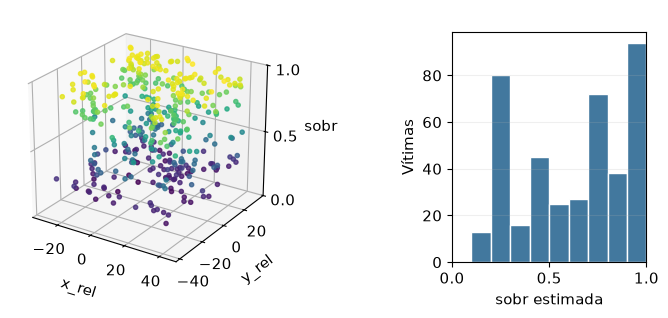

,Geometria observada
bloco_15_min,5.000000
bloco_15_max,41.000000
blocos_vazios,0.000000
vizinho_mais_proximo_mediana,1.000000
vizinho_mais_proximo_p90,3.162278
correlacao_x_sobr,-0.066075
correlacao_y_sobr,0.066962


In [6]:
X_principal, scaler_principal = padronizar(vitimas, PRINCIPAIS)
escala_principal = pd.DataFrame({
    "Característica": PRINCIPAIS, "Média": scaler_principal.mean_,
    "Desvio populacional": scaler_principal.scale_,
    "Média após padronização": X_principal.mean(axis=0),
    "Desvio após padronização": X_principal.std(axis=0, ddof=0),
})
display(escala_principal)
fig = plotar_espaco(vitimas, RESULTADOS / "espaco_caracteristicas.png")
plt.show()
plt.close(fig)

geometria = analisar_geometria(vitimas)
display(pd.Series(geometria, name="Geometria observada").to_frame())

### Distribuição dos dados e adequação do K-Means

As vítimas apresentam concentrações espaciais e regiões menos densas.
Os blocos de 15 × 15 células contêm de **5 a 41 vítimas**; a mediana da
distância ao vizinho mais próximo é **1 célula**. Essa heterogeneidade indica
que a ocupação do ambiente não é uniforme.

`sobr` varia de aproximadamente **0,164 a 0,967**, com concentrações em
faixas baixas e altas. Suas correlações com `x_rel` e `y_rel` são pequenas
(−0,066 e 0,067), indicando pouca associação linear com as coordenadas,
sem demonstrar independência. Assim, a terceira dimensão acrescenta uma
distinção que não se resume à localização.

O K-Means aproxima concentrações por centroides e define regiões de Voronoi
**convexas no espaço padronizado**: cada região reúne os pontos mais próximos
de um mesmo centro. Essa geometria permite uma aproximação por grupos compactos,
mas não prova que os agrupamentos naturais sejam esféricos. Densidades
diferentes, grupos alongados, lacunas ou formas não convexas podem levar a
divisões inadequadas. As métricas permitirão avaliar a separação obtida.

Além disso, a distância utilizada ignora paredes e dificuldade do terreno.
Pontos próximos podem exigir trajetos longos, e um centroide não é
necessariamente uma célula acessível ou um destino de resgate.

## 7. Avaliação do espaço principal e três parametrizações

Avaliamos novamente **K = 2–12**, agora mantendo fixos o espaço
`[x_rel, y_rel, sobr]`, sua padronização e os demais parâmetros. O cotovelo
indica K = 7; selecionamos **K = 6, 7 e 8** para comparar uma divisão menos
fragmentada, a solução indicada e uma divisão mais fragmentada nessa região.
Os três ajustes pertencem à mesma varredura.

K = 5 permanece como referência operacional, pois existem cinco socorristas,
mas a quantidade de grupos é determinada pelos dados. Nos gráficos, a região
sombreada identifica os três candidatos; a linha pontilhada marca K = 5 e
a tracejada, a parametrização selecionada pela maior silhueta global.

,K,SSE,silhueta
0,2,29.807694,0.276051
1,3,25.813621,0.295947
2,4,22.872890,0.329369
3,5,20.551380,0.330874
4,6,18.670041,0.355985
5,7,16.775219,0.376392
6,8,15.573485,0.373902
7,9,14.864288,0.368985
8,10,14.232954,0.366226
9,11,13.766945,0.355499


Cotovelo do espaço principal: 7
Três K comparados: [6, 7, 8]


,PAR,K,SSE,silhueta
0,1,6,18.670041,0.355985
1,2,7,16.775219,0.376392
2,3,8,15.573485,0.373902


,PAR,K,cobertura,score_final,silhuetas_negativas
0,1,6,1.000000,0.355985,10
1,2,7,1.000000,0.376392,9
2,3,8,1.000000,0.373902,4


Referência operacional K = 5:


,K,SSE,silhueta
3,5,20.551380,0.330874


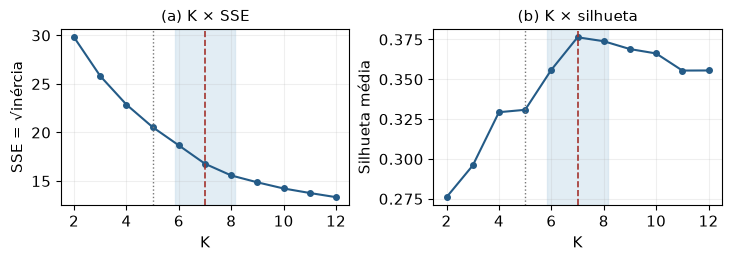

In [7]:
tabela_principal, modelos_principais, silhuetas_principais = avaliar_k(X_principal)
cotovelo_principal, distancias_principais = localizar_cotovelo(tabela_principal)
tabela_principal["distancia_cotovelo"] = distancias_principais
comparacao, melhor_k = comparar_parametrizacoes(tabela_principal, cotovelo_principal)
candidatos = comparacao.K.astype(int).tolist()
melhor_linha = comparacao.set_index("K").loc[melhor_k]
display(tabela_principal[["K", "SSE", "silhueta"]])
print("Cotovelo do espaço principal:", cotovelo_principal)
print("Três K comparados:", candidatos)
display(comparacao[["PAR", "K", "SSE", "silhueta"]])
display(comparacao[["PAR", "K", "cobertura", "score_final", "silhuetas_negativas"]])
print("Referência operacional K = 5:")
display(tabela_principal.loc[tabela_principal.K == 5, ["K", "SSE", "silhueta"]])
fig = plotar_avaliacao(
    tabela_principal, RESULTADOS / "avaliacao_principal.png", melhor_k, candidatos,
)
plt.show()
plt.close(fig)

### Silhuetas individuais, cobertura e score final

A média de silhueta pode ocultar vítimas com pertencimento ambíguo.
Por isso, examinamos também os **410 valores individuais** de cada
parametrização, mantendo inclusive os negativos no cálculo de $S_g$.

A cobertura corresponde à fração das vítimas de entrada que recebeu um
agrupamento, e o score combina essa abrangência com a separação média:

$$\mathrm{Cobertura}=\frac{N_{\mathrm{agrupadas}}}{410},\qquad
\mathrm{ScoreFinal}=S_g\times\mathrm{Cobertura}.$$

Como nenhuma vítima é excluída e K-Means atribui todas a algum cluster,
a cobertura é **1** nos três casos e ScoreFinal coincide com $S_g$.
Os identificadores dos clusters são apenas rótulos; sua numeração não indica
gravidade, prioridade ou sequência de atendimento.

Nos diagramas abaixo, cada faixa representa um cluster e seus pontos estão
ordenados pela silhueta. A altura da faixa acompanha a quantidade de vítimas;
a extensão horizontal mostra seus coeficientes. A linha vertical tracejada
indica a média global.

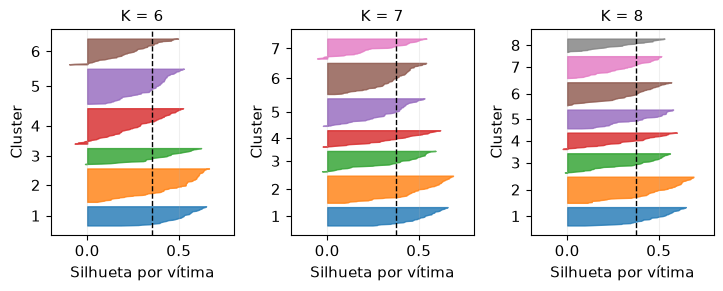

In [8]:
silhuetas_individuais = pd.concat([
    pd.DataFrame({
        "id": vitimas.id, "K": k, "cluster": numerar_clusters(modelos_principais[k]),
        "silhueta": silhuetas_principais[k],
    }) for k in candidatos
], ignore_index=True)
for k in candidatos:
    pontos = silhuetas_individuais.loc[silhuetas_individuais.K == k]
    assert len(pontos) == 410 and pontos.id.is_unique
    np.testing.assert_allclose(
        pontos.silhueta.mean(), comparacao.set_index("K").loc[k, "silhueta"], atol=1e-12,
    )
assert (comparacao.cobertura == 1).all()
np.testing.assert_allclose(comparacao.score_final, comparacao.silhueta)
fig = plotar_silhuetas(
    modelos_principais, silhuetas_principais, candidatos,
    RESULTADOS / "silhuetas_parametrizacoes.png",
)
plt.show()
plt.close(fig)

## 8. Seleção e caracterização do agrupamento

A maior silhueta global, equivalente ao maior score nesta comparação,
seleciona **K = 7**. Seu valor é **0,376392**, contra **0,355985** para K = 6
e **0,373902** para K = 8. A vantagem sobre K = 8 é pequena: a oitava
partição reduz SSE de 16,775219 para 15,573485, mas não melhora a separação
média. Em caso de empate exato no score, o critério adotado prefere o menor K.

A média não esgota a comparação. K = 7 apresenta **9 silhuetas negativas**,
enquanto K = 8 apresenta 4; portanto, a solução escolhida não domina todas as
medidas de ambiguidade. A separação obtida exige examinar os perfis dos grupos,
não apenas seu score agregado.

A tabela seguinte reúne tamanho, sobrevivência, posição média, silhueta
média, idade e composição START de cada grupo. Idade e `tri` caracterizam
o resultado, mas não participaram do espaço de características do K-Means.

In [9]:
vitimas["cluster"] = numerar_clusters(modelos_principais[melhor_k])
vitimas["silhueta"] = silhuetas_principais[melhor_k]
resumo_clusters = resumir_clusters(vitimas)
display(resumo_clusters)
np.testing.assert_allclose(
    silhouette_score(X_principal, vitimas.cluster), melhor_linha.silhueta, atol=1e-12,
)
display(Markdown(
    f"**K = {melhor_k} (PAR {int(melhor_linha.PAR)})** obteve a maior silhueta "
    f"entre os três candidatos: **{melhor_linha.silhueta:.6f}**. "
    f"SSE = {melhor_linha.SSE:.6f}; cobertura = {melhor_linha.cobertura:.0%}. "
    f"Os grupos têm de {resumo_clusters.vitimas.min()} a {resumo_clusters.vitimas.max()} vítimas. "
    f"Há {int(melhor_linha.silhuetas_negativas)} silhuetas negativas; elas indicam "
    "fronteiras ambíguas e limitam a separação obtida. O K selecionado descreve "
    "este conjunto e este critério, sem obrigar uma correspondência entre grupos e agentes."
))

,cluster,vitimas,ate_12,sobr_media,sobr_min,sobr_max,x_medio,y_medio,silhueta_media,tri_0,tri_1,tri_2,tri_3
0,1,47,19,0.842075,0.700405,0.960800,-13.148936,-19.872340,0.509176,20,26,1,0
1,2,69,21,0.855147,0.639234,0.961644,-11.898551,22.318841,0.483071,36,31,2,0
2,3,52,11,0.401086,0.179932,0.623868,-9.903846,20.480769,0.353961,0,0,33,19
3,4,42,6,0.333906,0.163757,0.598457,-7.738095,-19.880952,0.358530,0,0,20,22
4,5,70,7,0.312909,0.188821,0.576642,24.542857,7.628571,0.319215,0,0,24,46
5,6,79,28,0.836852,0.598498,0.967019,25.417722,9.911392,0.347729,39,30,10,0
6,7,51,14,0.627164,0.197161,0.961178,29.078431,-27.627451,0.270151,6,18,19,8


**K = 7 (PAR 2)** obteve a maior silhueta entre os três candidatos: **0.376392**. SSE = 16.775219; cobertura = 100%. Os grupos têm de 42 a 79 vítimas. Há 9 silhuetas negativas; elas indicam fronteiras ambíguas e limitam a separação obtida. O K selecionado descreve este conjunto e este critério, sem obrigar uma correspondência entre grupos e agentes.

## 9. Interpretação dos clusters no grid

A projeção no ambiente permite relacionar os perfis da tabela à localização.
O **contorno colorido da célula identifica o cluster** e a **cor do círculo
identifica a triagem predita**: verde (`tri = 0`), amarela (`tri = 1`),
vermelha (`tri = 2`) e preta (`tri = 3`). O fundo representa paredes e
dificuldade do terreno, e a estrela marca a base relativa `(0, 0)`.
O eixo vertical mantém a orientação das linhas do mapa, crescendo para baixo.

Como o agrupamento foi realizado em três dimensões, a proximidade na figura
2D não implica pertencimento ao mesmo grupo. Diferenças de `sobr` podem
separar vítimas próximas espacialmente. As cores START representam previsões
do classificador, não rótulos observados para validar a qualidade clínica.

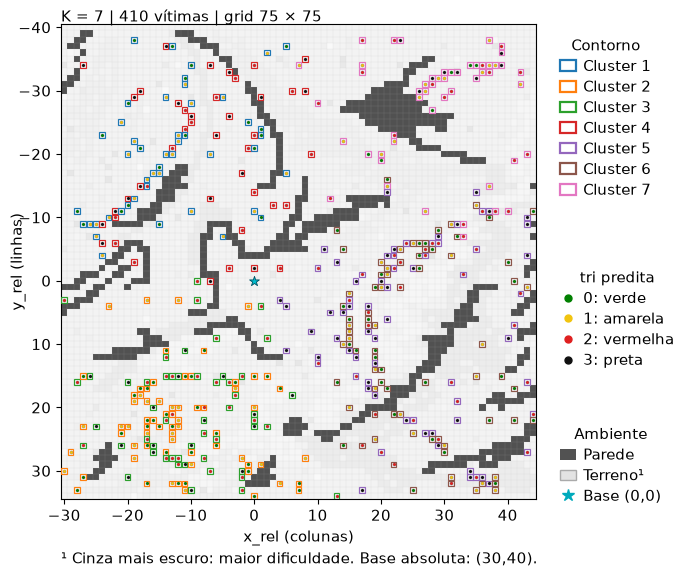

In [10]:
fig = plotar_grid(mapa, vitimas, RESULTADOS / "agrupamentos_grid.png")
plt.show()
plt.close(fig)

Os grupos contêm de **42 a 79 vítimas**. C1 e C4 ocupam regiões próximas,
mas suas sobrevivências médias são aproximadamente **0,842 e 0,334**;
C2 e C3 apresentam diferença semelhante (**0,855 e 0,401**). Na região
à direita da base, C5 e C6 também contrastam (**0,313 e 0,837**).
Essas sobreposições na projeção ilustram o efeito de incluir `sobr`
no agrupamento.

C7 reúne perfis mais variados e possui a menor silhueta média entre os
grupos (**0,270**), mostrando que a qualidade da separação não é uniforme.
Todos os clusters contêm vítimas de até 12 anos, de **6 a 28 por grupo**;
assim, seus limites não correspondem diretamente às capacidades dos agentes.
As diferenças de sobrevivência e triagem descrevem os grupos, sem determinar
por si só uma ordem de atendimento.

## 10. Representação e exportação dos agrupamentos

Cada `cluster_i.txt` representa o conjunto de vítimas de um grupo, com um
identificador por linha. A ordenação numérica dos IDs facilita a consulta,
mas não define sequência de socorro. A partição deve conter as 410 vítimas,
sem repetição entre grupos: esse vínculo preserva a identidade de cada vítima
para análises e decisões posteriores.

Durante a análise, os DataFrames relacionam cada ID às coordenadas,
previsões, cluster e silhueta individual. As tabelas e os resumos estatísticos
permitem estudar os grupos sem alterar os sinais vitais originais. Os arquivos
texto representam a partição final a ser utilizada na etapa de socorro.

In [11]:
validacao_arquivos = exportar_clusters(vitimas, RESULTADOS, melhor_k)
assert tabela_espacial.K.tolist() == tabela_principal.K.tolist() == list(range(2, 13))
assert len(comparacao) == comparacao.K.nunique() == 3
display(pd.Series(validacao_arquivos, name="Exportação validada").to_frame())

,Exportação validada
arquivos,7
vitimas,410
duplicatas,0
ids_invalidos,0


## 11. Relação com a estratégia de socorro

Os sete grupos organizam proximidade e condição estimada, enquanto a
atribuição aos **cinco agentes** deverá considerar capacidades, urgência,
posição atual e carga de trabalho. Um agente poderá atuar em mais de um grupo,
e diferentes agentes poderão atender vítimas distintas de um mesmo grupo
em paralelo. O número de clusters pode variar entre cenários, permanecendo
fixo nesta análise.

As restrições de idade impedem uma atribuição indiscriminada: **agentes 1 e 2
atendem todas as idades; agentes 3, 4 e 5 atendem apenas idade > 12**.
Há **106 vítimas de até 12 anos**, distribuídas pelos sete grupos. Em grupos
mistos, essas vítimas deverão ser reservadas a 1/2, enquanto os adultos
poderão ser distribuídos também a 3–5. Reservas compartilhadas poderiam
evitar atendimentos duplicados e apoiar a redistribuição de pendências.

No cenário START, a triagem orienta a urgência: vermelhas demandam atenção
imediata, seguidas de amarelas e verdes; pretas não entram automaticamente
na fila de salvamento. Dentro de cada classe elegível, a sobrevivência
estimada poderá apoiar a avaliação de viabilidade junto ao tempo de
deslocamento e ao benefício esperado. **Menor `sobr` não implica maior
prioridade**: o regressor não estima o ganho causal do atendimento, e uma
alta previsão de sobrevivência não elimina a urgência de outra vítima.

Essa proposta ainda exige lidar com incertezas das previsões e calcular
custos de deslocamento em caminhos transitáveis. Os agrupamentos constituem
uma entrada para a próxima tarefa, que tratará da atribuição e do
sequenciamento; essas decisões não são executadas pelo clustering.

## 12. Discussão e conclusões

O experimento espacial favorece **K = 5**, com silhueta **0,480188**;
ao incluir sobrevivência, o espaço principal favorece **K = 7**, com
silhueta **0,376392** e cobertura integral. A diferença de silhueta entre
os espaços não permite concluir, isoladamente, que um critério seja melhor
para socorro: cada experimento mede distâncias e separação em uma
representação diferente. A terceira dimensão introduz distinções de
condição estimada que a posição, sozinha, não expressa.

A solução principal reúne todas as vítimas, mas mantém fronteiras ambíguas
e grupos com composições distintas. A padronização define a importância
relativa das características; as previsões supervisionadas carregam seus
próprios erros; e a geometria convexa do K-Means aproxima apenas parte da
estrutura observada. Cobertura de 100% significa inclusão de todas as
vítimas, não demonstra acessibilidade dos grupos nem eficácia do resgate.

O resultado organiza informações para uma etapa operacional posterior.
Avaliar tempos de deslocamento, elegibilidade dos agentes, benefício do
atendimento e coordenação permitirá investigar como esses agrupamentos
podem apoiar uma sequência de socorro.

Referências: [enunciado da Tarefa 3](docs/enunciados/TO3_enunciado_cluster.pdf),
[K-Means e inércia](https://scikit-learn.org/stable/modules/clustering.html#k-means),
[coeficiente de silhueta](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_samples.html)
e [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).